In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [2]:
import pandas as pd 

data = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")
data.to_csv("submission.csv", index=False)
data.sample(10)

,ID,Prediction
241,242,A B C
496,497,A B C
268,269,A B C
99,100,A B C
156,157,A B C
464,465,A B C
257,258,A B C
74,75,A B C
475,476,A B C
235,236,A B C


In [3]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

## EDA(Exploratory data analysis)

In [4]:
train.describe()

,id
count,2000.000000
mean,1000.500000
std,577.494589
min,1.000000
25%,500.750000
50%,1000.500000
75%,1500.250000
max,2000.000000


In [5]:
test.describe()


,id
count,500.000000
mean,250.500000
std,144.481833
min,1.000000
25%,125.750000
50%,250.500000
75%,375.250000
max,500.000000


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


In [7]:
test.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      500 non-null    int64 
 1   prompt  500 non-null    object
 2   A       500 non-null    object
 3   B       500 non-null    object
 4   C       500 non-null    object
 5   D       500 non-null    object
 6   E       500 non-null    object
dtypes: int64(1), object(6)
memory usage: 27.5+ KB


In [8]:
train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [9]:
test.head()

,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


In [10]:
train.describe(include='all')

,id,prompt,A,B,C,D,E,answer
count,2000.000000,2000,2000,2000,2000,2000,2000,2000
unique,NaN,1758,316,328,303,318,320,5
top,NaN,Choose the correct answer: What is the main se...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,B
freq,NaN,4,21,21,21,21,21,490
mean,1000.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,577.494589,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,500.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1000.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1500.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
train.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [12]:
train.duplicated().sum()

np.int64(0)

In [13]:
freq = train["answer"].value_counts()

## Visualization


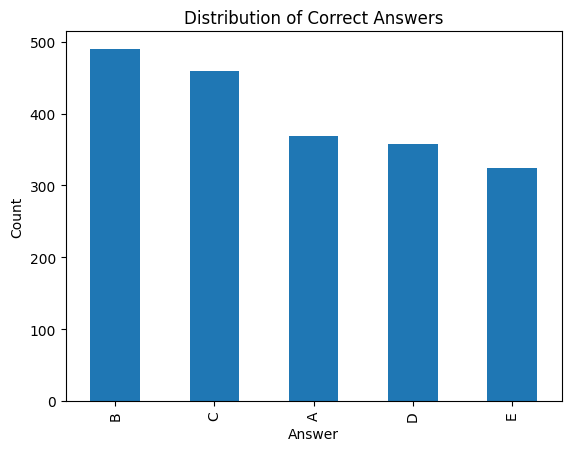

In [14]:
# Answer distribuition

import matplotlib.pyplot as plt

freq.plot.bar()
plt.title("Distribution of Correct Answers")
plt.xlabel("Answer")
plt.ylabel("Count")
plt.show()

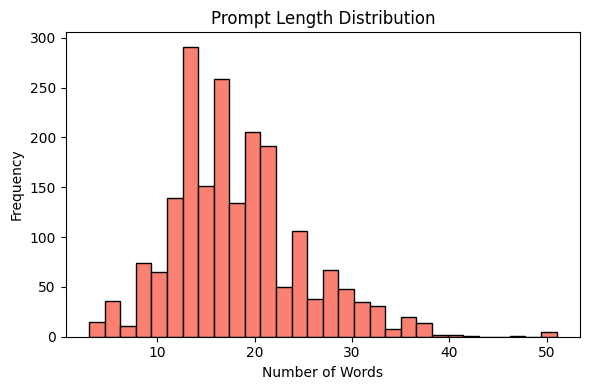

In [15]:
# Prompt length distribuition

train["prompt_length"] = train["prompt"].str.split().str.len()

plt.figure(figsize=(6, 4))
plt.hist(train["prompt_length"], bins=30, color="salmon", edgecolor="black")
plt.title("Prompt Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## Preprocessing

The preprocessing pipeline performs:

- Lowercasing
- Removing punctuation
- Tokenization
- Stop-word removal

In [16]:
import string
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

In [17]:
# Clean text (lowercase + remove punctuation)

def clean_text(text):
    text = str(text).lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    return text

In [18]:
train["clean_prompt"] = train["prompt"].apply(clean_text)

In [19]:
# Tokenization (split by whitespace)

train["tokens"] = train["clean_prompt"].apply(lambda x: x.split())

In [20]:
# Remove stop words

train["filtered_tokens"] = train["tokens"].apply(
    lambda words: [w for w in words if w not in ENGLISH_STOP_WORDS]
)

In [21]:
train[["prompt", "clean_prompt", "tokens", "filtered_tokens"]].head(3)

,prompt,clean_prompt,tokens,filtered_tokens
0,Pick the best possible answer: What is Martin ...,pick the best possible answer what is martin h...,"[pick, the, best, possible, answer, what, is, ...","[pick, best, possible, answer, martin, heidegg..."
1,What is accelerator-based light-ion fusion?,what is acceleratorbased lightion fusion,"[what, is, acceleratorbased, lightion, fusion]","[acceleratorbased, lightion, fusion]"
2,Determine the correct option: What is the term...,determine the correct option what is the term ...,"[determine, the, correct, option, what, is, th...","[determine, correct, option, term, used, astro..."


In [22]:
import sentence_transformers

print(sentence_transformers.__version__)

5.4.0


In [23]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

print("Loaded Successfully!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded Successfully!


In [ ]:
!pip install -q sentence-transformers

In [33]:
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer, CrossEncoder
from sentence_transformers.util import cos_sim

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OPTIONS = ["A", "B", "C", "D", "E"]
print("Device:", DEVICE)

Device: cuda


In [38]:
def map_at_3(answer, prediction):
    for rank, pred in enumerate(prediction[:3], start=1):
        if pred == answer:
            return 1 / rank
    return 0

def evaluate_map3(train_df, all_preds):
    scores = [
        map_at_3(train_df.iloc[i]["answer"], all_preds[i])
        for i in range(len(train_df))
    ]
    return round(np.mean(scores), 4)

## Model 1 — TF-IDF + Cosine Similarity (From Scratch)

In [39]:
# Build corpus
corpus = []
for _, row in train.iterrows():
    corpus.append(" ".join([row["prompt"], row["A"], row["B"],
                             row["C"], row["D"], row["E"]]))

# Fit TF-IDF
tfidf = TfidfVectorizer(stop_words="english")
tfidf.fit(corpus)

TfidfVectorizer(stop_words='english')

In [28]:
def tfidf_rank(row):
    prompt_vec = tfidf.transform([row["prompt"]])
    scores = {}
    for opt in OPTIONS:
        opt_vec = tfidf.transform([row[opt]])
        scores[opt] = cosine_similarity(prompt_vec, opt_vec)[0][0]
    return sorted(scores, key=scores.get, reverse=True)

model1_preds = [tfidf_rank(row) for _, row in train.iterrows()]
model1_map3  = evaluate_map3(train, model1_preds)
print(f"Model 1 — TF-IDF MAP@3: {model1_map3}")

Model 1 — TF-IDF MAP@3: 0.2962


## Model 2 — all-MiniLM-L6-v2 (Pretrained Sentence Transformer)

In [29]:
minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
print("MiniLM loaded on", DEVICE, "✅")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


MiniLM loaded on cuda ✅


In [30]:
# Batch encode all prompts
print("Encoding prompts...")
prompt_embs = minilm.encode(
    train["prompt"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_tensor=True,
    device=DEVICE
)

# Batch encode all options
option_embs = {}
for opt in OPTIONS:
    print(f"Encoding option {opt}...")
    option_embs[opt] = minilm.encode(
        train[opt].tolist(),
        batch_size=64,
        show_progress_bar=False,
        convert_to_tensor=True,
        device=DEVICE
    )
print("All encodings done ✅")

Encoding prompts...


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Encoding option A...
Encoding option B...
Encoding option C...
Encoding option D...
Encoding option E...
All encodings done ✅


In [40]:
def minilm_rank(i):
    scores = {
        opt: cos_sim(prompt_embs[i], option_embs[opt][i]).item()
        for opt in OPTIONS
    }
    return sorted(scores, key=scores.get, reverse=True)

model2_preds = [minilm_rank(i) for i in range(len(train))]
model2_map3  = evaluate_map3(train, model2_preds)
print(f"Model 2 — MiniLM MAP@3: {model2_map3}")

Model 2 — MiniLM MAP@3: 0.4231


## Model 3 — RACE Finetuned RoBERTa (Choice Model)

In [41]:
cross_encoder = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2",
    device=DEVICE
)
print(f"Model 3 (cross-encoder/ms-marco-MiniLM-L-6-v2) loaded on {DEVICE} ✅")

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Model 3 (cross-encoder/ms-marco-MiniLM-L-6-v2) loaded on cuda ✅


In [42]:
def cross_encoder_rank(row):
    prompt  = str(row["prompt"])
    pairs   = [(prompt, str(row[opt])) for opt in OPTIONS]
    scores  = cross_encoder.predict(pairs)          # returns numpy array of 5 scores
    scored  = {OPTIONS[i]: float(scores[i]) for i in range(5)}
    return sorted(scored, key=scored.get, reverse=True)


# Build train cross-encoder scores in batch (faster than row-by-row)
print("Building cross-encoder pairs for train...")
all_pairs  = []
pair_index = []   # track which (row_idx, opt_idx) each pair belongs to

for i, (_, row) in enumerate(train.iterrows()):
    prompt = str(row["prompt"])
    for j, opt in enumerate(OPTIONS):
        all_pairs.append((prompt, str(row[opt])))
        pair_index.append((i, j))

print(f"Total pairs: {len(all_pairs)}  (2000 rows × 5 options)")

# Predict all at once in large batches
print("Running cross-encoder predictions (GPU)...")
all_scores = cross_encoder.predict(
    all_pairs,
    batch_size=256,
    show_progress_bar=True
)
print("Cross-encoder scoring done ✅")

# Reshape into per-row scores
ce_train_scores = []
for i in range(len(train)):
    row_scores = {OPTIONS[j]: float(all_scores[i * 5 + j]) for j in range(5)}
    ce_train_scores.append(row_scores)

Building cross-encoder pairs for train...
Total pairs: 10000  (2000 rows × 5 options)
Running cross-encoder predictions (GPU)...


Batches:   0%|          | 0/40 [00:00<?, ?it/s]

Cross-encoder scoring done ✅


In [43]:
def ce_rank_from_scores(i):
    return sorted(ce_train_scores[i], key=ce_train_scores[i].get, reverse=True)

model3_preds = [ce_rank_from_scores(i) for i in range(len(train))]
model3_map3  = evaluate_map3(train, model3_preds)
print(f"Model 3 — CrossEncoder MAP@3: {model3_map3}")

Model 3 — CrossEncoder MAP@3: 0.4631


In [45]:
def get_minilm_scores(i, pembs, oembs):
    raw   = {opt: cos_sim(pembs[i], oembs[opt][i]).item() for opt in OPTIONS}
    mn, mx = min(raw.values()), max(raw.values())
    denom  = (mx - mn) if mx != mn else 1e-9
    return {opt: (raw[opt] - mn) / denom for opt in OPTIONS}

def get_ce_scores_normalized(scores_dict):
    mn, mx = min(scores_dict.values()), max(scores_dict.values())
    denom  = (mx - mn) if mx != mn else 1e-9
    return {opt: (scores_dict[opt] - mn) / denom for opt in OPTIONS}

def ensemble_rank(i, pembs, oembs, ce_scores_list, w_minilm=0.3, w_ce=0.7):
    m_scores = get_minilm_scores(i, pembs, oembs)
    c_scores = get_ce_scores_normalized(ce_scores_list[i])
    fused = {
        opt: w_minilm * m_scores[opt] + w_ce * c_scores[opt]
        for opt in OPTIONS
    }
    return sorted(fused, key=fused.get, reverse=True)

In [46]:
print("Running Ensemble on train...")

ensemble_preds = []
for i in range(len(train)):
    ensemble_preds.append(
        ensemble_rank(i, prompt_embs, option_embs, ce_train_scores)
    )
    if (i + 1) % 200 == 0:
        print(f"  {i+1}/2000 done...")

ensemble_map3 = evaluate_map3(train, ensemble_preds)
print(f"Ensemble MAP@3: {ensemble_map3}")

Running Ensemble on train...
  200/2000 done...
  400/2000 done...
  600/2000 done...
  800/2000 done...
  1000/2000 done...
  1200/2000 done...
  1400/2000 done...
  1600/2000 done...
  1800/2000 done...
  2000/2000 done...
Ensemble MAP@3: 0.4668


In [47]:
print("=" * 50)
print(f"  Model 1  TF-IDF              MAP@3 : {model1_map3}")
print(f"  Model 2  MiniLM              MAP@3 : {model2_map3}")
print(f"  Model 3  RoBERTa/RACE        MAP@3 : {model3_map3}")
print(f"  Ensemble (Model2 + Model3)   MAP@3 : {ensemble_map3}")
print("=" * 50)

  Model 1  TF-IDF              MAP@3 : 0.2962
  Model 2  MiniLM              MAP@3 : 0.4231
  Model 3  RoBERTa/RACE        MAP@3 : 0.4631
  Ensemble (Model2 + Model3)   MAP@3 : 0.4668


In [48]:
# Encode test set with MiniLM
print("Encoding test prompts with MiniLM...")
test_prompt_embs = minilm.encode(
    test["prompt"].tolist(),
    batch_size=64, show_progress_bar=True,
    convert_to_tensor=True, device=DEVICE
)
test_option_embs = {}
for opt in OPTIONS:
    test_option_embs[opt] = minilm.encode(
        test[opt].tolist(),
        batch_size=64, show_progress_bar=False,
        convert_to_tensor=True, device=DEVICE
    )
print("MiniLM test encodings done ✅")

# Build cross-encoder pairs for test
print("Building cross-encoder pairs for test...")
test_all_pairs = []
for _, row in test.iterrows():
    prompt = str(row["prompt"])
    for opt in OPTIONS:
        test_all_pairs.append((prompt, str(row[opt])))

print(f"Total test pairs: {len(test_all_pairs)}  (500 rows × 5 options)")

print("Running cross-encoder on test (GPU)...")
test_all_scores = cross_encoder.predict(
    test_all_pairs,
    batch_size=256,
    show_progress_bar=True
)

# Reshape into per-row scores
ce_test_scores = []
for i in range(len(test)):
    row_scores = {OPTIONS[j]: float(test_all_scores[i * 5 + j]) for j in range(5)}
    ce_test_scores.append(row_scores)

print("Cross-encoder test scoring done ✅")

Encoding test prompts with MiniLM...


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

MiniLM test encodings done ✅
Building cross-encoder pairs for test...
Total test pairs: 2500  (500 rows × 5 options)
Running cross-encoder on test (GPU)...


Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Cross-encoder test scoring done ✅


In [49]:
# Generate ensemble predictions for test
print("Generating final predictions...")

predictions = []
for i in range(len(test)):
    ranked = ensemble_rank(
        i,
        test_prompt_embs, test_option_embs,
        ce_test_scores
    )
    predictions.append({
        "ID": test.iloc[i]["id"],
        "Prediction": " ".join(ranked[:3])
    })
    if (i + 1) % 100 == 0:
        print(f"  {i+1}/500 done...")

submission = pd.DataFrame(predictions)
submission.to_csv("submission.csv", index=False)
print("submission.csv saved ✅")
submission.head(10)

Generating final predictions...
  100/500 done...
  200/500 done...
  300/500 done...
  400/500 done...
  500/500 done...
submission.csv saved ✅


,ID,Prediction
0,1,B A E
1,2,B E C
2,3,A C D
3,4,E C A
4,5,B C A
5,6,E A B
6,7,E C D
7,8,C B E
8,9,C A E
9,10,C E D
